# Road Accident Pattern Analysis in India

**Data source:** Ministry of Road Transport and Highways (MoRTH), *Road Accidents in India 2023*.

## Project scope
This notebook analyses curated **aggregated official statistics**, not individual crash records. Each CSV table is a published summary by category, year or time interval.

## Questions
1. Which 3-hour interval has the largest number of reported accidents?
2. How are accidents distributed by severity?
3. How do accident counts, deaths and injuries differ by road category?
4. Which weather categories have the highest reported accident counts?
5. How have accidents and fatalities changed over time?
6. How do monthly and rural/urban distributions compare?

## Before you run the notebook
**You only need this one `.ipynb` file.** The seven small CSV tables are included in the first setup cell below. You do not need to download or upload a separate ZIP file or seven separate CSV files.

## Important limitation
These are aggregate tables. They do not contain an individual row for every crash, exact timestamps, crash IDs, GPS coordinates or traffic-exposure data. The analysis is descriptive and does not prove causation.


## 1. Import libraries and prepare data

### Setup
Run the next cell once. It creates the seven CSV files from the data bundled inside this notebook. No file picker or ZIP upload is required.

In [1]:
from pathlib import Path
from io import StringIO
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# The seven small CSV tables below are bundled with this notebook.
# They were transcribed/curated from the MoRTH Road Accidents in India 2023 report.
# They are aggregated statistics, not individual crash-level records.
CSV_TABLES = {
    'national_trends_2019_2023.csv': 'year,total_accidents,fatal_accidents,persons_killed,persons_injured,source_table,source_page,source_url\n2019,456959,145332,158984,449360,Table 1.1 / Table 4.1 / Table 7.1,"6, 51, 92",https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2020,372181,127307,138383,346747,Table 1.1 / Table 4.1 / Table 7.1,"6, 51, 92",https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2021,412432,142163,153972,384448,Table 1.1 / Table 4.1 / Table 7.1,"6, 51, 92",https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2022,461312,155781,168491,443366,Table 1.1 / Table 4.1 / Table 7.1,"6, 51, 92",https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2023,480583,160509,172890,462825,Table 1.1 / Table 4.1 / Table 7.1,"6, 51, 92",https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n',
    'severity_2019_2023.csv': 'year,severity_category,accidents,share_pct,source_table,source_page,source_url\n2019,Fatal accidents,145332,31.8,Table 1.4,9,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2019,Grievous-injury accidents,151335,33.12,Table 1.4,9,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2019,Minor-injury accidents,131555,28.79,Table 1.4,9,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2019,Non-injury accidents,28737,6.29,Table 1.4,9,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2020,Fatal accidents,127307,34.21,Table 1.4,9,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2020,Grievous-injury accidents,112768,30.3,Table 1.4,9,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2020,Minor-injury accidents,110314,29.64,Table 1.4,9,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2020,Non-injury accidents,21792,5.86,Table 1.4,9,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2021,Fatal accidents,142163,34.47,Table 1.4,9,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2021,Grievous-injury accidents,126394,30.65,Table 1.4,9,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2021,Minor-injury accidents,119633,29.01,Table 1.4,9,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2021,Non-injury accidents,24242,5.88,Table 1.4,9,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2022,Fatal accidents,155781,33.77,Table 1.4,9,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2022,Grievous-injury accidents,143374,31.08,Table 1.4,9,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2022,Minor-injury accidents,135360,29.34,Table 1.4,9,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2022,Non-injury accidents,26797,5.81,Table 1.4,9,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2023,Fatal accidents,160509,33.4,Table 1.4,9,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2023,Grievous-injury accidents,158576,33.0,Table 1.4,9,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2023,Minor-injury accidents,133848,27.85,Table 1.4,9,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2023,Non-injury accidents,27650,5.75,Table 1.4,9,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n',
    'road_category_2022_2023.csv': 'year,road_category,accidents,persons_killed,persons_injured,accidents_share_pct,killed_share_pct,injured_share_pct,source_table,source_page,source_url\n2022,National Highways,151997,61038,144352,32.95,36.23,32.56,Table 2.1,23,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2022,State Highways,106682,41012,106485,23.13,24.34,24.02,Table 2.1,23,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2022,Other Roads,202633,66441,192529,43.93,39.43,43.42,Table 2.1,23,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2023,National Highways,150177,63112,143031,31.25,36.5,30.9,Table 2.1,23,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2023,State Highways,105662,39439,107120,21.99,22.81,23.14,Table 2.1,23,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2023,Other Roads,224744,70339,212674,46.76,40.68,45.95,Table 2.1,23,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n',
    'weather_2022_2023.csv': 'year,weather_condition,accidents,persons_killed,persons_injured,accident_share_pct,killed_share_pct,injured_share_pct,source_table,source_page,source_url\n2022,Sunny/clear,342516,119585,332586,74.25,70.97,75.01,Table 3.8,48,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2022,Rainy,38329,14773,36950,8.31,8.77,8.33,Table 3.8,48,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2022,Foggy and misty,34262,14583,30796,7.43,8.66,6.95,Table 3.8,48,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2022,Hail/sleet,4083,1871,3621,0.89,1.11,0.82,Table 3.8,48,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2022,Others,42122,17679,39413,9.13,10.49,8.89,Table 3.8,48,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2023,Sunny/clear,365865,125065,359074,76.13,72.34,77.58,Table 3.8,48,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2023,Rainy,37316,13734,36102,7.76,7.94,7.8,Table 3.8,48,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2023,Foggy and misty,34266,14617,30646,7.13,8.45,6.62,Table 3.8,48,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2023,Hail/sleet,3378,1516,3064,0.7,0.88,0.66,Table 3.8,48,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2023,Others,39758,17958,33939,8.27,10.39,7.33,Table 3.8,48,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n',
    'time_interval_2019_2023.csv': 'year,time_interval,period,accidents,share_pct,source_table,source_page,source_url\n2019,06:00-09:00 (Day),Day,50119,11.0,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2020,06:00-09:00 (Day),Day,40431,10.9,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2021,06:00-09:00 (Day),Day,43370,10.5,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2022,06:00-09:00 (Day),Day,48304,10.5,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2023,06:00-09:00 (Day),Day,48872,10.2,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2019,09:00-12:00 (Day),Day,68267,14.9,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2020,09:00-12:00 (Day),Day,55474,14.9,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2021,09:00-12:00 (Day),Day,61387,14.9,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2022,09:00-12:00 (Day),Day,65664,14.2,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2023,09:00-12:00 (Day),Day,67580,14.1,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2019,12:00-15:00 (Day),Day,68361,15.0,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2020,12:00-15:00 (Day),Day,56570,15.2,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2021,12:00-15:00 (Day),Day,63139,15.3,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2022,12:00-15:00 (Day),Day,67979,14.7,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2023,12:00-15:00 (Day),Day,71697,14.9,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2019,15:00-18:00 (Day),Day,78935,17.3,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2020,15:00-18:00 (Day),Day,65676,17.6,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2021,15:00-18:00 (Day),Day,73467,17.8,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2022,15:00-18:00 (Day),Day,79637,17.3,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2023,15:00-18:00 (Day),Day,84479,17.6,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2019,18:00-21:00 (Night),Night,86503,18.9,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2020,18:00-21:00 (Night),Night,74198,19.9,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2021,18:00-21:00 (Night),Night,85179,20.7,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2022,18:00-21:00 (Night),Night,94009,20.4,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2023,18:00-21:00 (Night),Night,99945,20.8,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2019,21:00-24:00 (Night),Night,50016,10.9,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2020,21:00-24:00 (Night),Night,37693,10.1,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2021,21:00-24:00 (Night),Night,41092,10.0,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2022,21:00-24:00 (Night),Night,52915,11.5,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2023,21:00-24:00 (Night),Night,55157,11.5,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2019,00:00-03:00 (Night),Night,24827,5.4,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2020,00:00-03:00 (Night),Night,18466,5.0,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2021,00:00-03:00 (Night),Night,19682,4.8,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2022,00:00-03:00 (Night),Night,23471,5.1,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2023,00:00-03:00 (Night),Night,24298,5.1,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2019,03:00-06:00 (Night),Night,26527,5.8,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2020,03:00-06:00 (Night),Night,19782,5.3,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2021,03:00-06:00 (Night),Night,20120,4.9,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2022,03:00-06:00 (Night),Night,24152,5.2,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2023,03:00-06:00 (Night),Night,22794,4.7,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2019,Unknown time,Unknown,3404,0.7,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2020,Unknown time,Unknown,3891,1.0,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2021,Unknown time,Unknown,4996,1.2,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2022,Unknown time,Unknown,5181,1.1,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2023,Unknown time,Unknown,5761,1.2,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n',
    'monthly_2023.csv': 'month,accidents,persons_killed,year,source_table,source_page,source_url\nJan,41841,14610,2023,Chart 7.3,95,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\nFeb,39022,14279,2023,Chart 7.3,95,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\nMar,40549,14907,2023,Chart 7.3,95,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\nApr,39138,14438,2023,Chart 7.3,95,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\nMay,43578,16718,2023,Chart 7.3,95,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\nJun,40968,15253,2023,Chart 7.3,95,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\nJul,38088,13381,2023,Chart 7.3,95,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\nAug,38466,12843,2023,Chart 7.3,95,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\nSep,38143,12732,2023,Chart 7.3,95,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\nOct,40018,13822,2023,Chart 7.3,95,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\nNov,39775,14524,2023,Chart 7.3,95,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\nDec,40997,15383,2023,Chart 7.3,95,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n',
    'rural_urban_2019_2023.csv': 'year,area,accidents,persons_killed,persons_injured,source_table,source_page,source_url\n2019,Urban,184287,52836,169928,Table 7.1,92,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2019,Rural,272672,106148,279432,Table 7.1,92,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2020,Urban,143686,44323,126337,Table 7.1,92,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2020,Rural,228495,94097,221356,Table 7.1,92,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2021,Urban,152586,47235,134719,Table 7.1,92,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2021,Rural,259846,106737,249729,Table 7.1,92,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2022,Urban,177269,54230,159444,Table 7.1,92,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2022,Rural,284043,114261,283922,Table 7.1,92,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2023,Urban,188330,54479,171034,Table 7.1,92,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n2023,Rural,292253,118411,291791,Table 7.1,92,https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf\n',
}

# Store the bundled CSVs in the current Colab session.
DATA_DIR = Path("/content/india_road_accident_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

for file_name, csv_text in CSV_TABLES.items():
    (DATA_DIR / file_name).write_text(csv_text, encoding="utf-8")

OUT_DIR = Path("/content/india_road_accident_visualizations")
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Loaded {len(CSV_TABLES)} CSV tables into: {DATA_DIR}")
print("No separate ZIP or CSV upload is needed.")

Loaded 7 CSV tables into: /content/india_road_accident_data
No separate ZIP or CSV upload is needed.


## 2. Load the CSV tables

In [2]:
annual = pd.read_csv(DATA_DIR / "national_trends_2019_2023.csv")
severity = pd.read_csv(DATA_DIR / "severity_2019_2023.csv")
road = pd.read_csv(DATA_DIR / "road_category_2022_2023.csv")
weather = pd.read_csv(DATA_DIR / "weather_2022_2023.csv")
time = pd.read_csv(DATA_DIR / "time_interval_2019_2023.csv")
monthly = pd.read_csv(DATA_DIR / "monthly_2023.csv")
rural_urban = pd.read_csv(DATA_DIR / "rural_urban_2019_2023.csv")

print("National trend:", annual.shape)
print("Severity table:", severity.shape)
print("Road category table:", road.shape)
print("Weather table:", weather.shape)
print("Time interval table:", time.shape)
print("Monthly table:", monthly.shape)
print("Rural/urban table:", rural_urban.shape)
display(annual)


National trend: (5, 8)
Severity table: (20, 7)
Road category table: (6, 11)
Weather table: (10, 11)
Time interval table: (45, 8)
Monthly table: (12, 7)
Rural/urban table: (10, 8)


,year,total_accidents,fatal_accidents,persons_killed,persons_injured,source_table,source_page,source_url
0,2019,456959,145332,158984,449360,Table 1.1 / Table 4.1 / Table 7.1,"6, 51, 92",https://morth.nic.in/sites/default/files/Road-...
1,2020,372181,127307,138383,346747,Table 1.1 / Table 4.1 / Table 7.1,"6, 51, 92",https://morth.nic.in/sites/default/files/Road-...
2,2021,412432,142163,153972,384448,Table 1.1 / Table 4.1 / Table 7.1,"6, 51, 92",https://morth.nic.in/sites/default/files/Road-...
3,2022,461312,155781,168491,443366,Table 1.1 / Table 4.1 / Table 7.1,"6, 51, 92",https://morth.nic.in/sites/default/files/Road-...
4,2023,480583,160509,172890,462825,Table 1.1 / Table 4.1 / Table 7.1,"6, 51, 92",https://morth.nic.in/sites/default/files/Road-...


## 3. Understand the data structure

In [3]:
display(annual.head())
display(time[time["year"] == 2023].head(10))
print("Time table columns:", time.columns.tolist())
print("Weather table data types:")
print(weather.dtypes)


,year,total_accidents,fatal_accidents,persons_killed,persons_injured,source_table,source_page,source_url
0,2019,456959,145332,158984,449360,Table 1.1 / Table 4.1 / Table 7.1,"6, 51, 92",https://morth.nic.in/sites/default/files/Road-...
1,2020,372181,127307,138383,346747,Table 1.1 / Table 4.1 / Table 7.1,"6, 51, 92",https://morth.nic.in/sites/default/files/Road-...
2,2021,412432,142163,153972,384448,Table 1.1 / Table 4.1 / Table 7.1,"6, 51, 92",https://morth.nic.in/sites/default/files/Road-...
3,2022,461312,155781,168491,443366,Table 1.1 / Table 4.1 / Table 7.1,"6, 51, 92",https://morth.nic.in/sites/default/files/Road-...
4,2023,480583,160509,172890,462825,Table 1.1 / Table 4.1 / Table 7.1,"6, 51, 92",https://morth.nic.in/sites/default/files/Road-...


,year,time_interval,period,accidents,share_pct,source_table,source_page,source_url
4,2023,06:00-09:00 (Day),Day,48872,10.2,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-...
9,2023,09:00-12:00 (Day),Day,67580,14.1,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-...
14,2023,12:00-15:00 (Day),Day,71697,14.9,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-...
19,2023,15:00-18:00 (Day),Day,84479,17.6,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-...
24,2023,18:00-21:00 (Night),Night,99945,20.8,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-...
29,2023,21:00-24:00 (Night),Night,55157,11.5,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-...
34,2023,00:00-03:00 (Night),Night,24298,5.1,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-...
39,2023,03:00-06:00 (Night),Night,22794,4.7,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-...
44,2023,Unknown time,Unknown,5761,1.2,Table 7.3,96,https://morth.nic.in/sites/default/files/Road-...


Time table columns: ['year', 'time_interval', 'period', 'accidents', 'share_pct', 'source_table', 'source_page', 'source_url']
Weather table data types:
year                    int64
weather_condition      object
accidents               int64
persons_killed          int64
persons_injured         int64
accident_share_pct    float64
killed_share_pct      float64
injured_share_pct     float64
source_table           object
source_page             int64
source_url             object
dtype: object


## 4. Data quality checks

In [4]:
tables = {
    "annual": annual, "severity": severity, "road": road,
    "weather": weather, "time": time, "monthly": monthly,
    "rural_urban": rural_urban
}

quality_rows = []
for name, table in tables.items():
    quality_rows.append({
        "table": name,
        "rows": len(table),
        "columns": len(table.columns),
        "missing_cells": int(table.isna().sum().sum()),
        "exact_duplicate_rows": int(table.duplicated().sum())
    })
quality = pd.DataFrame(quality_rows)
display(quality)


,table,rows,columns,missing_cells,exact_duplicate_rows
0,annual,5,8,0,0
1,severity,20,7,0,0
2,road,6,11,0,0
3,weather,10,11,0,0
4,time,45,8,0,0
5,monthly,12,7,0,0
6,rural_urban,10,8,0,0


### 4.1 Reconcile grouped totals with published national totals

In [5]:
checks = []
def add_check(name, observed, expected, note):
    checks.append({"check": name, "observed": int(observed), "expected": int(expected),
                   "passed": int(observed) == int(expected), "note": note})

for year in [2019, 2020, 2021, 2022, 2023]:
    expected = int(annual.loc[annual.year == year, "total_accidents"].iloc[0])
    observed = int(time.loc[time.year == year, "accidents"].sum())
    add_check(f"Time intervals including unknown - {year}", observed, expected,
              "All 3-hour categories plus unknown time should equal the national total.")

for year in [2022, 2023]:
    expected = int(annual.loc[annual.year == year, "total_accidents"].iloc[0])
    add_check(f"Weather categories - {year}", weather.loc[weather.year == year, "accidents"].sum(), expected,
              "Published weather categories should reconcile to the national total.")
    add_check(f"Road categories - {year}", road.loc[road.year == year, "accidents"].sum(), expected,
              "Published road categories should reconcile to the national total.")
    add_check(f"Severity categories - {year}", severity.loc[severity.year == year, "accidents"].sum(), expected,
              "Severity categories should reconcile to the national total.")

expected_2023 = int(annual.loc[annual.year == 2023, "total_accidents"].iloc[0])
add_check("Monthly totals - 2023", monthly.accidents.sum(), expected_2023,
          "Month-wise accident counts should equal annual total.")
expected_killed = int(annual.loc[annual.year == 2023, "persons_killed"].iloc[0])
add_check("Monthly killed - 2023", monthly.persons_killed.sum(), expected_killed,
          "Month-wise killed counts should equal annual total.")
for metric, annual_col in [("accidents", "total_accidents"), ("persons_killed", "persons_killed"), ("persons_injured", "persons_injured")]:
    observed = rural_urban.loc[rural_urban.year == 2023, metric].sum()
    expected = annual.loc[annual.year == 2023, annual_col].iloc[0]
    add_check(f"Rural + urban {metric} - 2023", observed, expected,
              "Rural and urban subtotals should equal All India annual total.")

reconciliation = pd.DataFrame(checks)
display(reconciliation)
assert reconciliation["passed"].all(), "At least one reconciliation check failed; review the source transcription."
print("All reconciliation checks passed.")


,check,observed,expected,passed,note
0,Time intervals including unknown - 2019,456959,456959,True,All 3-hour categories plus unknown time should...
1,Time intervals including unknown - 2020,372181,372181,True,All 3-hour categories plus unknown time should...
2,Time intervals including unknown - 2021,412432,412432,True,All 3-hour categories plus unknown time should...
3,Time intervals including unknown - 2022,461312,461312,True,All 3-hour categories plus unknown time should...
4,Time intervals including unknown - 2023,480583,480583,True,All 3-hour categories plus unknown time should...
5,Weather categories - 2022,461312,461312,True,Published weather categories should reconcile ...
6,Road categories - 2022,461312,461312,True,Published road categories should reconcile to ...
7,Severity categories - 2022,461312,461312,True,Severity categories should reconcile to the na...
8,Weather categories - 2023,480583,480583,True,Published weather categories should reconcile ...
9,Road categories - 2023,480583,480583,True,Published road categories should reconcile to ...


All reconciliation checks passed.


### Data-quality interpretation
The exact duplicate and missing-value checks apply to these curated aggregate tables. They do **not** prove that the underlying police submissions have no duplicates or missing records. No incident ID is provided in the aggregate report tables, so individual accident de-duplication is not possible.


## 5. Exploratory Data Analysis (EDA)

In [6]:
# 2023 national totals
row_2023 = annual.loc[annual.year == 2023].iloc[0]
print(f"2023 accidents: {row_2023.total_accidents:,.0f}")
print(f"2023 fatal accidents: {row_2023.fatal_accidents:,.0f}")
print(f"2023 persons killed: {row_2023.persons_killed:,.0f}")
print(f"2023 persons injured: {row_2023.persons_injured:,.0f}")

# Highest time interval in 2023
time_2023 = time[time.year == 2023].sort_values("accidents", ascending=False)
display(time_2023[["time_interval", "accidents", "share_pct"]])

# Severity and weather summaries
display(severity[severity.year == 2023][["severity_category", "accidents", "share_pct"]])
display(weather[weather.year == 2023][["weather_condition", "accidents", "accident_share_pct"]])


2023 accidents: 480,583
2023 fatal accidents: 160,509
2023 persons killed: 172,890
2023 persons injured: 462,825


,time_interval,accidents,share_pct
24,18:00-21:00 (Night),99945,20.8
19,15:00-18:00 (Day),84479,17.6
14,12:00-15:00 (Day),71697,14.9
9,09:00-12:00 (Day),67580,14.1
29,21:00-24:00 (Night),55157,11.5
4,06:00-09:00 (Day),48872,10.2
34,00:00-03:00 (Night),24298,5.1
39,03:00-06:00 (Night),22794,4.7
44,Unknown time,5761,1.2


,severity_category,accidents,share_pct
16,Fatal accidents,160509,33.40
17,Grievous-injury accidents,158576,33.00
18,Minor-injury accidents,133848,27.85
19,Non-injury accidents,27650,5.75


,weather_condition,accidents,accident_share_pct
5,Sunny/clear,365865,76.13
6,Rainy,37316,7.76
7,Foggy and misty,34266,7.13
8,Hail/sleet,3378,0.70
9,Others,39758,8.27


## 6. Visualizations

In [7]:
sns.set_theme(style="whitegrid")


### Chart 1 - Accidents by time interval (2023)

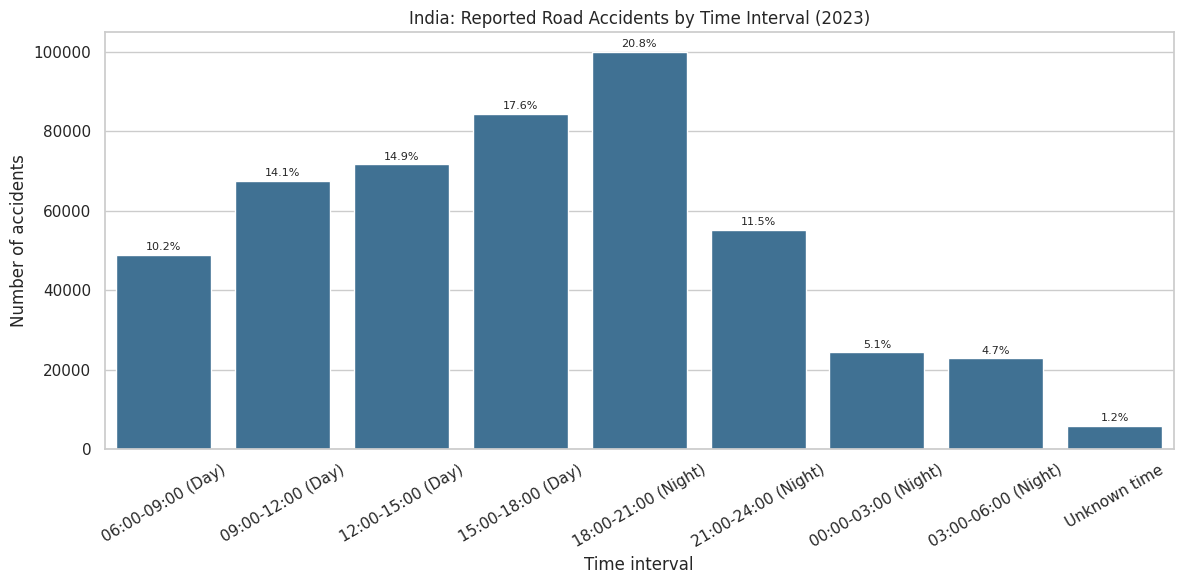

In [8]:
time_order = [
    "06:00-09:00 (Day)", "09:00-12:00 (Day)", "12:00-15:00 (Day)",
    "15:00-18:00 (Day)", "18:00-21:00 (Night)", "21:00-24:00 (Night)",
    "00:00-03:00 (Night)", "03:00-06:00 (Night)", "Unknown time"
]
p = time[time.year == 2023].copy()
p["time_interval"] = pd.Categorical(p.time_interval, categories=time_order, ordered=True)
p = p.sort_values("time_interval")
plt.figure(figsize=(12, 6))
ax = sns.barplot(data=p, x="time_interval", y="accidents", color="#3274A1")
ax.set_title("India: Reported Road Accidents by Time Interval (2023)")
ax.set_xlabel("Time interval"); ax.set_ylabel("Number of accidents")
ax.tick_params(axis="x", rotation=30)
for i, row in enumerate(p.itertuples()):
    ax.text(i, row.accidents + 1200, f"{row.share_pct:.1f}%", ha="center", fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / "01_accidents_by_time_interval_2023.png", dpi=180, bbox_inches="tight"); plt.show()


### Chart 2 - Severity distribution (2023)

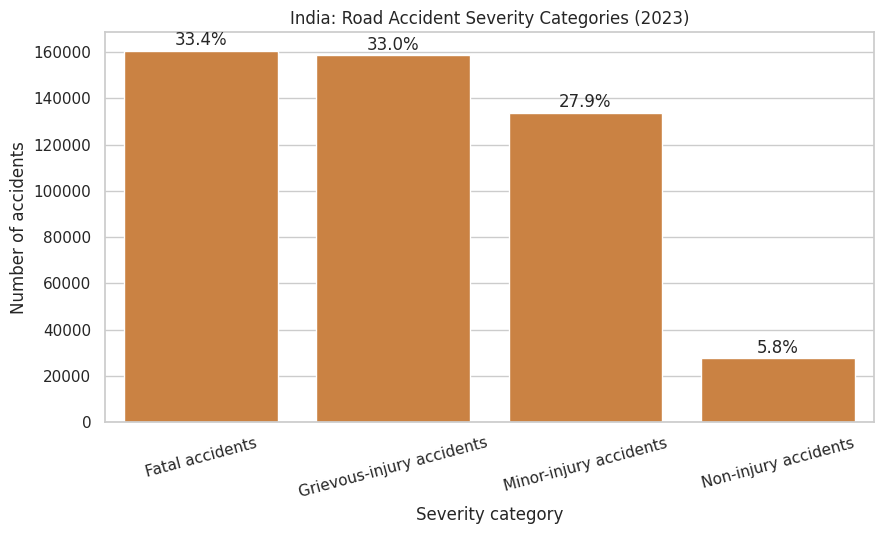

In [9]:
p = severity[severity.year == 2023].sort_values("accidents", ascending=False)
plt.figure(figsize=(9, 5.5))
ax = sns.barplot(data=p, x="severity_category", y="accidents", color="#E1812C")
ax.set_title("India: Road Accident Severity Categories (2023)")
ax.set_xlabel("Severity category"); ax.set_ylabel("Number of accidents")
ax.tick_params(axis="x", rotation=15)
for i, row in enumerate(p.itertuples()): ax.text(i, row.accidents + 2500, f"{row.share_pct:.1f}%", ha="center")
plt.tight_layout(); plt.savefig(OUT_DIR / "02_severity_distribution_2023.png", dpi=180, bbox_inches="tight"); plt.show()


### Chart 3 - Weather conditions (2023)

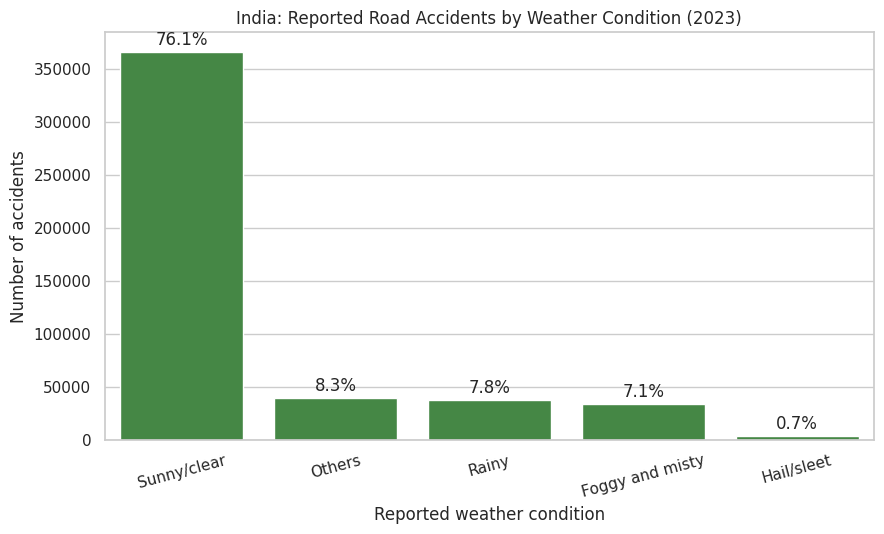

In [10]:
p = weather[weather.year == 2023].sort_values("accidents", ascending=False)
plt.figure(figsize=(9, 5.5))
ax = sns.barplot(data=p, x="weather_condition", y="accidents", color="#3A923A")
ax.set_title("India: Reported Road Accidents by Weather Condition (2023)")
ax.set_xlabel("Reported weather condition"); ax.set_ylabel("Number of accidents")
ax.tick_params(axis="x", rotation=15)
for i, row in enumerate(p.itertuples()): ax.text(i, row.accidents + 6500, f"{row.accident_share_pct:.1f}%", ha="center")
plt.tight_layout(); plt.savefig(OUT_DIR / "03_weather_conditions_2023.png", dpi=180, bbox_inches="tight"); plt.show()


### Chart 4 - Road category comparison (2023)

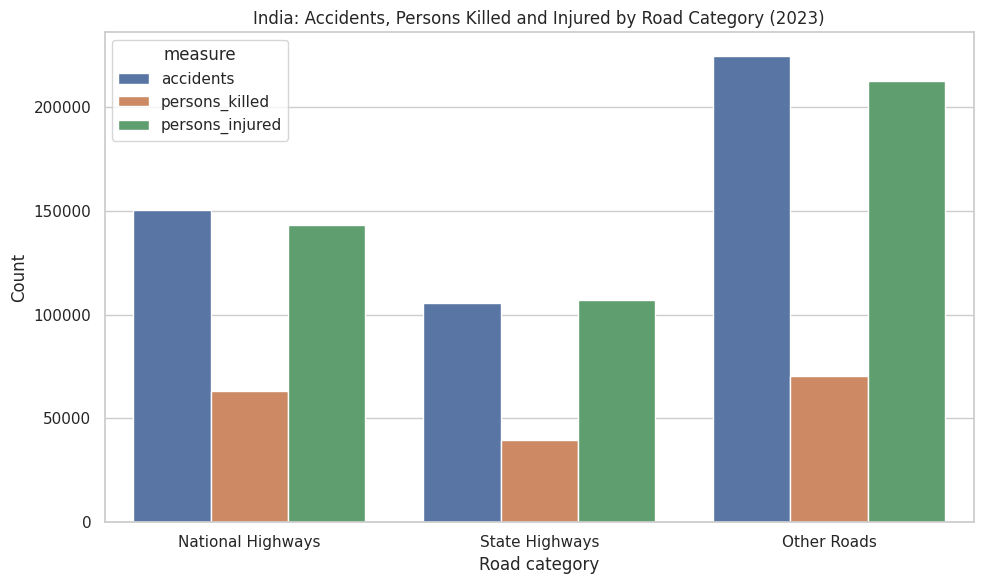

In [11]:
p = road[road.year == 2023].copy()
long_road = p.melt(id_vars="road_category", value_vars=["accidents", "persons_killed", "persons_injured"],
                   var_name="measure", value_name="count")
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=long_road, x="road_category", y="count", hue="measure")
ax.set_title("India: Accidents, Persons Killed and Injured by Road Category (2023)")
ax.set_xlabel("Road category"); ax.set_ylabel("Count")
plt.tight_layout(); plt.savefig(OUT_DIR / "04_road_category_2023.png", dpi=180, bbox_inches="tight"); plt.show()


### Chart 5 - Annual trends (2019-2023)

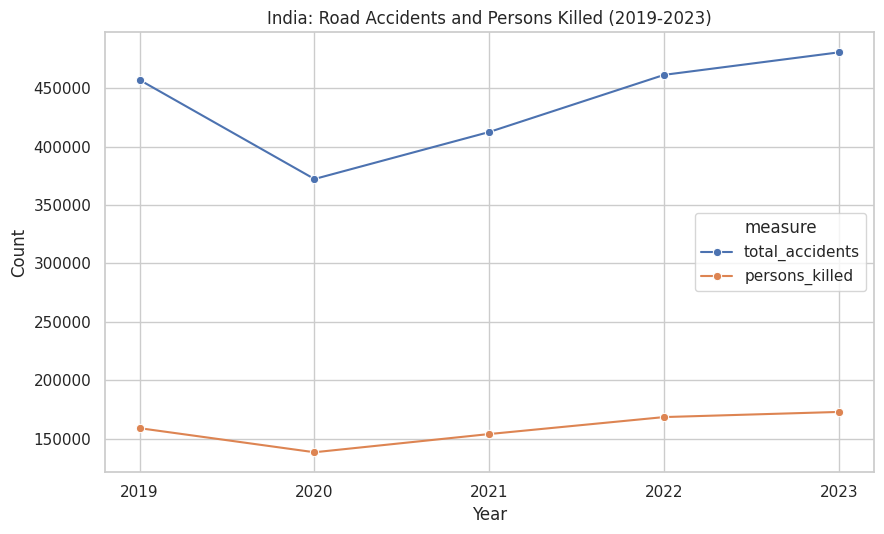

In [12]:
trend = annual.melt(id_vars="year", value_vars=["total_accidents", "persons_killed"],
                    var_name="measure", value_name="count")
plt.figure(figsize=(9, 5.5))
ax = sns.lineplot(data=trend, x="year", y="count", hue="measure", marker="o")
ax.set_title("India: Road Accidents and Persons Killed (2019-2023)")
ax.set_xlabel("Year"); ax.set_ylabel("Count"); ax.set_xticks(annual.year)
plt.tight_layout(); plt.savefig(OUT_DIR / "05_annual_trends_2019_2023.png", dpi=180, bbox_inches="tight"); plt.show()


### Chart 6 - Monthly trends (2023)

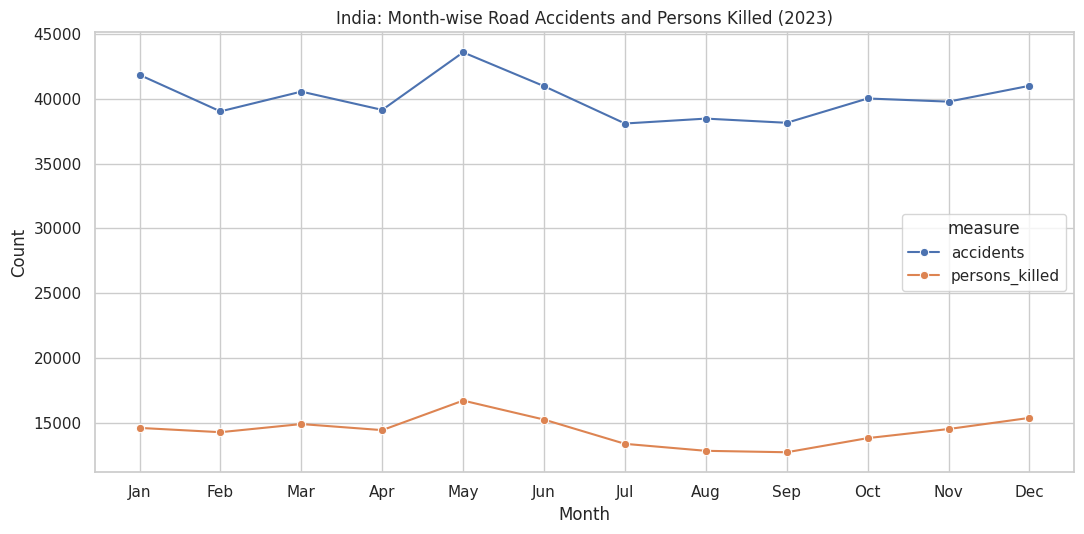

In [13]:
monthly_long = monthly.melt(id_vars=["month"], value_vars=["accidents", "persons_killed"],
                           var_name="measure", value_name="count")
plt.figure(figsize=(11, 5.5))
ax = sns.lineplot(data=monthly_long, x="month", y="count", hue="measure", marker="o")
ax.set_title("India: Month-wise Road Accidents and Persons Killed (2023)")
ax.set_xlabel("Month"); ax.set_ylabel("Count")
plt.tight_layout(); plt.savefig(OUT_DIR / "06_monthly_trends_2023.png", dpi=180, bbox_inches="tight"); plt.show()


### Chart 7 - Rural and urban distribution (2023)

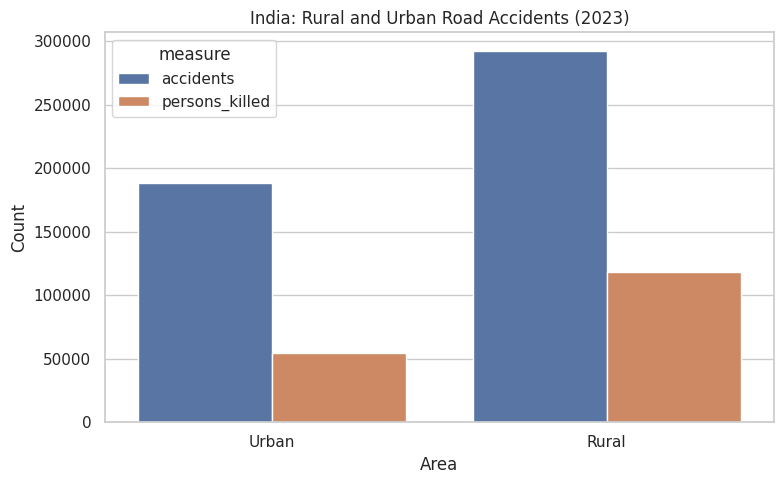

In [14]:
p = rural_urban[rural_urban.year == 2023].melt(id_vars="area", value_vars=["accidents", "persons_killed"],
                                                    var_name="measure", value_name="count")
plt.figure(figsize=(8, 5))
ax = sns.barplot(data=p, x="area", y="count", hue="measure")
ax.set_title("India: Rural and Urban Road Accidents (2023)")
ax.set_xlabel("Area"); ax.set_ylabel("Count")
plt.tight_layout(); plt.savefig(OUT_DIR / "07_rural_urban_2023.png", dpi=180, bbox_inches="tight"); plt.show()


## 7. Key findings (computed from the loaded CSV tables)

In [15]:
tmax = time_2023.iloc[0]
tmin = time_2023[time_2023.time_interval != "Unknown time"].sort_values("accidents").iloc[0]
sev23 = severity[severity.year == 2023].sort_values("accidents", ascending=False)
weather23 = weather[weather.year == 2023].sort_values("accidents", ascending=False)
road23 = road[road.year == 2023].sort_values("accidents", ascending=False)
month_max = monthly.loc[monthly.accidents.idxmax()]
month_min = monthly.loc[monthly.accidents.idxmin()]

print(f"Highest time interval: {tmax.time_interval} - {tmax.accidents:,.0f} ({tmax.share_pct:.1f}%)")
print(f"Lowest known time interval: {tmin.time_interval} - {tmin.accidents:,.0f} ({tmin.share_pct:.1f}%)")
print("Severity distribution:")
display(sev23[["severity_category", "accidents", "share_pct"]])
print(f"Largest weather category by count: {weather23.iloc[0].weather_condition} ({weather23.iloc[0].accidents:,.0f})")
print(f"Largest road category by count: {road23.iloc[0].road_category} ({road23.iloc[0].accidents:,.0f})")
print(f"Highest month: {month_max.month} ({month_max.accidents:,.0f}); lowest month: {month_min.month} ({month_min.accidents:,.0f})")


Highest time interval: 18:00-21:00 (Night) - 99,945 (20.8%)
Lowest known time interval: 03:00-06:00 (Night) - 22,794 (4.7%)
Severity distribution:


,severity_category,accidents,share_pct
16,Fatal accidents,160509,33.40
17,Grievous-injury accidents,158576,33.00
18,Minor-injury accidents,133848,27.85
19,Non-injury accidents,27650,5.75


Largest weather category by count: Sunny/clear (365,865)
Largest road category by count: Other Roads (224,744)
Highest month: May (43,578); lowest month: Jul (38,088)


## 8. Limitations and responsible interpretation

- The CSV tables are aggregated summaries. They do not contain individual accident records.
- The published time field is a 3-hour interval, not an exact timestamp; date/time parsing is not possible.
- This notebook checks exact duplicate rows in the curated summaries, not duplicate underlying incidents.
- Accident counts are not risk rates. Traffic volume and vehicle-kilometres are not included.
- Observed weather/time/road-category patterns are descriptive associations, not proof of causation.
- Arithmetic reconciliation of totals does not prove that all local incidents were reported.


## 9. Source and attribution

Ministry of Road Transport and Highways, Government of India, *Road Accidents in India 2023*.

Official report: https://morth.nic.in/sites/default/files/Road-Accident-in-India-2023-Publications.pdf

See `docs/SOURCE_NOTES.md` and `data/DATA_DICTIONARY.md` in the project repository for table/page mapping and field definitions.
